# Relaxed domain pattern in the PbTiO$_3$/SrTiO$_3$ superlattice

This notebook reads the dipole dumps sampled at 10 K and makes the same cuts as Fig. 3 of Zatterin et al., Phys. Rev. X **14**, 041052 (2024).

That figure asks whether the 180° walls are ordinary flux-closure (Néel) walls or carry a Bloch component:

- $P_z$ is out-of-plane in the domain interiors.
- At a flux-closure wall the in-plane polarization is **perpendicular** to the wall and is largest near the PbTiO$_3$/SrTiO$_3$ interface.
- A Bloch wall instead has in-plane polarization **parallel** to the wall, in the middle of the PbTiO$_3$ layer.

Each dump stores the local dipole in e·Å. The plotted field is the time average of the 10 K samples, in e·Å. Run this notebook from `examples/cooling_PTOSTO`.

In [1]:
%matplotlib inline

from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt
from matplotlib.colors import TwoSlopeNorm

plt.rcParams.update({
    "figure.dpi": 300,
    "font.size": 11,
    "axes.labelsize": 12,
    "image.interpolation": "nearest",
})

NOTEBOOK_DIR = Path.cwd()
OUTPUT_DIR = NOTEBOOK_DIR / "output_L2000_PTO12_STO12"
SAMPLE_TEMPERATURE_K = 10.0
if not (OUTPUT_DIR / f"sample_{SAMPLE_TEMPERATURE_K:g}K.log").is_file():
    raise FileNotFoundError(
        "Run this notebook from examples/cooling_PTOSTO, "
        f"after the {SAMPLE_TEMPERATURE_K:g} K sampling dumps are written."
    )

PTO_LAYERS = 12
DT_PS = 0.002
WINDOW = 40

In [2]:
def sample_dumps(output_dir, temperature_k):
    """Return sample_{T}K_dump_*.npy paths in time order."""
    label = f"{temperature_k:g}"
    files = sorted(
        output_dir.glob(f"sample_{label}K_dump_*.npy"),
        key=lambda path: int(path.stem.rsplit("_", 1)[1]),
    )
    if not files:
        raise FileNotFoundError(
            f"No sample_{label}K_dump_*.npy files in {output_dir}"
        )
    return files


dump_paths = sample_dumps(OUTPUT_DIR, SAMPLE_TEMPERATURE_K)
dipole_sum = np.zeros(
    np.load(dump_paths[0], mmap_mode="r").shape, dtype=np.float64
)
for dump_path in dump_paths:
    dipole_sum += np.load(dump_path)
dipole = dipole_sum / len(dump_paths)
nx, ny, nz, _ = dipole.shape
if PTO_LAYERS < 1 or PTO_LAYERS >= nz:
    raise ValueError(f"PTO_LAYERS must lie in 1..{nz - 1}, got {PTO_LAYERS}.")
middle_layer = PTO_LAYERS // 2
top_layer = PTO_LAYERS - 1
sample_times_ps = np.array([
    int(path.stem.rsplit("_", 1)[1]) * DT_PS for path in dump_paths
])
print(
    f"{len(dump_paths)} samples at {SAMPLE_TEMPERATURE_K:g} K, "
    f"t = {sample_times_ps[0]:.0f}..{sample_times_ps[-1]:.0f} ps, "
    f"{nx}x{ny}x{nz}\n"
    f"PbTiO3 layers z = 0..{top_layer}, middle z = {middle_layer}, "
    f"top interface z = {top_layer}"
)

11 samples at 10 K, t = 0..10 ps, 2000x2000x24
PbTiO3 layers z = 0..11, middle z = 6, top interface z = 11


In [3]:
def most_structured_window(pz, window):
    """Upper-left corner of the window whose pz has the largest variance."""
    if window > pz.shape[0] or window > pz.shape[1]:
        raise ValueError("WINDOW is larger than the lateral lattice.")
    best = None
    for x0 in range(0, pz.shape[0] - window + 1, window):
        for y0 in range(0, pz.shape[1] - window + 1, window):
            variance = pz[x0:x0 + window, y0:y0 + window].var()
            if best is None or variance > best[0]:
                best = (variance, x0, y0)
    return best[1], best[2]


x0, y0 = most_structured_window(dipole[:, :, middle_layer, 2], WINDOW)
y_cut = y0 + WINDOW // 2
print(f"Window x = {x0}..{x0 + WINDOW - 1}, y = {y0}..{y0 + WINDOW - 1}; x-z cut at y = {y_cut}")

Window x = 1200..1239, y = 440..479; x-z cut at y = 460


## Cuts corresponding to Fig. 3(a)–(c)

The four panels use one 32×32 block, the lateral patch whose middle-layer $p_z$ varies the most. The upper row is the $x$-$z$ cut through the middle of that block. Its $z$ coordinate is shifted so the PbTiO$_3$ layers are centered and SrTiO$_3$ lies equally above and below; the horizontal lines are the two interfaces. The lower row is the middle of the PbTiO$_3$ layer and its top interface with SrTiO$_3$. Color is one dipole component, in e·Å. The arrow at each lattice site is the local dipole projected onto that plane, scaled separately in each panel so a long arrow is shorter than one cell.

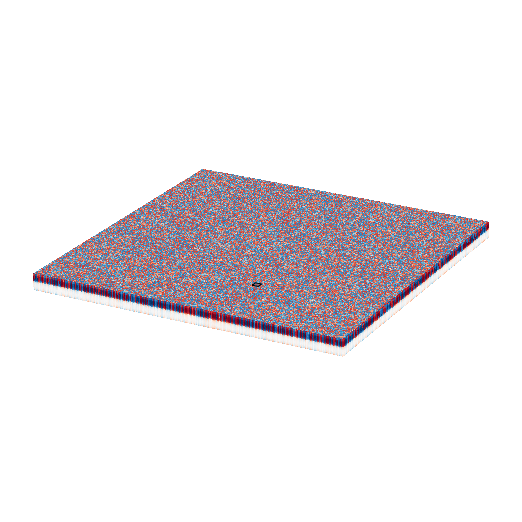

In [4]:
def symmetric_norm(values):
    limit = np.percentile(np.abs(values), 99)
    limit = max(float(limit), 1.0e-8)
    return TwoSlopeNorm(vmin=-limit, vcenter=0.0, vmax=limit)


def show_xy(ax, field, origin_x, origin_y, norm):
    width_x, width_y = field.shape
    image = ax.imshow(
        field.T,
        origin="lower",
        extent=(
            origin_x - 0.5,
            origin_x + width_x - 0.5,
            origin_y - 0.5,
            origin_y + width_y - 0.5,
        ),
        norm=norm,
        cmap="RdBu_r",
        aspect="equal",
    )
    return image


def quiver_scale(vectors):
    """Return a scale that keeps a long arrow shorter than one cell."""
    lengths = np.linalg.norm(np.asarray(vectors), axis=-1)
    typical = float(np.percentile(lengths, 98))
    return max(typical , 1.0e-8)


def quiver_plane(ax, origin, horizontal, vertical):
    """Draw the in-plane dipole at every site.

    ``horizontal`` and ``vertical`` are the dipole components along the two
    plotted axes, each shaped ``(n_horizontal, n_vertical)``. ``origin`` is
    the lattice index of the first site on each axis. The arrow scale is
    chosen for this panel so a long dipole is shorter than one cell.
    """
    n_horizontal, n_vertical = horizontal.shape
    horizontal_index = np.arange(origin[0], origin[0] + n_horizontal)
    vertical_index = np.arange(origin[1], origin[1] + n_vertical)
    horizontal_grid, vertical_grid = np.meshgrid(
        horizontal_index, vertical_index, indexing="ij"
    )
    ax.quiver(
        horizontal_grid,
        vertical_grid,
        horizontal,
        vertical,
        angles="xy",
        scale_units="xy",
        scale=quiver_scale(np.stack((horizontal, vertical), axis=-1)),
        pivot="middle",
        width=0.004,
        color="k",
        alpha=0.9,
    )


window = dipole[x0:x0 + WINDOW, y0:y0 + WINDOW]
color_norm = symmetric_norm(window[:, :, :PTO_LAYERS])
# Roll z so the PbTiO3 block sits in the middle of the stack. Site
# coordinates are then measured from the center of that block.
pto_origin = (nz - PTO_LAYERS) // 2
z_center = pto_origin + (PTO_LAYERS - 1) / 2.0
section = np.roll(dipole[x0:x0 + WINDOW, y_cut], pto_origin, axis=1)

### Plot the entire system as a 3D object
# Physical z = 0 is the bottom PbTiO3 layer. Reverse z so that layer is the
# top face and SrTiO3 occupies the lower half of the cube.
face_step = max(1, int(np.ceil(max(nx, ny) / 700)))
pz_box = np.asarray(dipole[::face_step, ::face_step, ::-1, 2])
x_face = np.arange(0, nx, face_step, dtype=float)
y_face = np.arange(0, ny, face_step, dtype=float)
# Stretch z only enough to see the layers. The displayed stack stays a thin film.
displayed_thickness = 0.05 * nx
z_scale = displayed_thickness / (nz - 1)
z_face = np.arange(nz) * z_scale
domain_norm = symmetric_norm(pz_box[:, :, PTO_LAYERS:])
domain_cmap = plt.get_cmap("RdBu_r")

def face_colors(field):
    return domain_cmap(domain_norm(field))[:-1, :-1]

def draw_face(ax, x_grid, y_grid, z_grid, field):
    ax.plot_surface(
        x_grid,
        y_grid,
        z_grid,
        facecolors=face_colors(field),
        rstride=1,
        cstride=1,
        shade=False,
        linewidth=0,
        antialiased=False,
    )

fig = plt.figure(figsize=(8, 2))
ax = fig.add_subplot(111, projection="3d", proj_type="persp")
xx, yy = np.meshgrid(x_face, y_face, indexing="ij")
draw_face(ax, xx, yy, np.full_like(xx, z_face[-1]), pz_box[:, :, -1])
xx, zz = np.meshgrid(x_face, z_face, indexing="ij")
draw_face(ax, xx, np.zeros_like(xx), zz, pz_box[:, 0, :])
yy, zz = np.meshgrid(y_face, z_face, indexing="ij")
draw_face(ax, np.full_like(yy, x_face[-1]), yy, zz, pz_box[-1, :, :])

window_x = [x0, x0 + WINDOW, x0 + WINDOW, x0, x0]
window_y = [y0, y0, y0 + WINDOW, y0 + WINDOW, y0]
# Sit the outline just above the top face so the surface does not cover it.
z_mark = displayed_thickness * 1.03
ax.plot(
    window_x,
    window_y,
    np.full(5, z_mark),
    color="k",
    lw=0.25,
    solid_capstyle="butt",
    solid_joinstyle="miter",
    zorder=5,
)
ax.view_init(elev=22, azim=-62)
ax.set_box_aspect((nx, ny, displayed_thickness))
ax.set_xlim(0, nx)
ax.set_ylim(0, ny)
ax.set_zlim(0, z_mark)
ax.set_axis_off()
fig.savefig("figures/system_3d.png", dpi=800, bbox_inches="tight", facecolor="white")
plt.show()


$p_z$ on $y = 460$


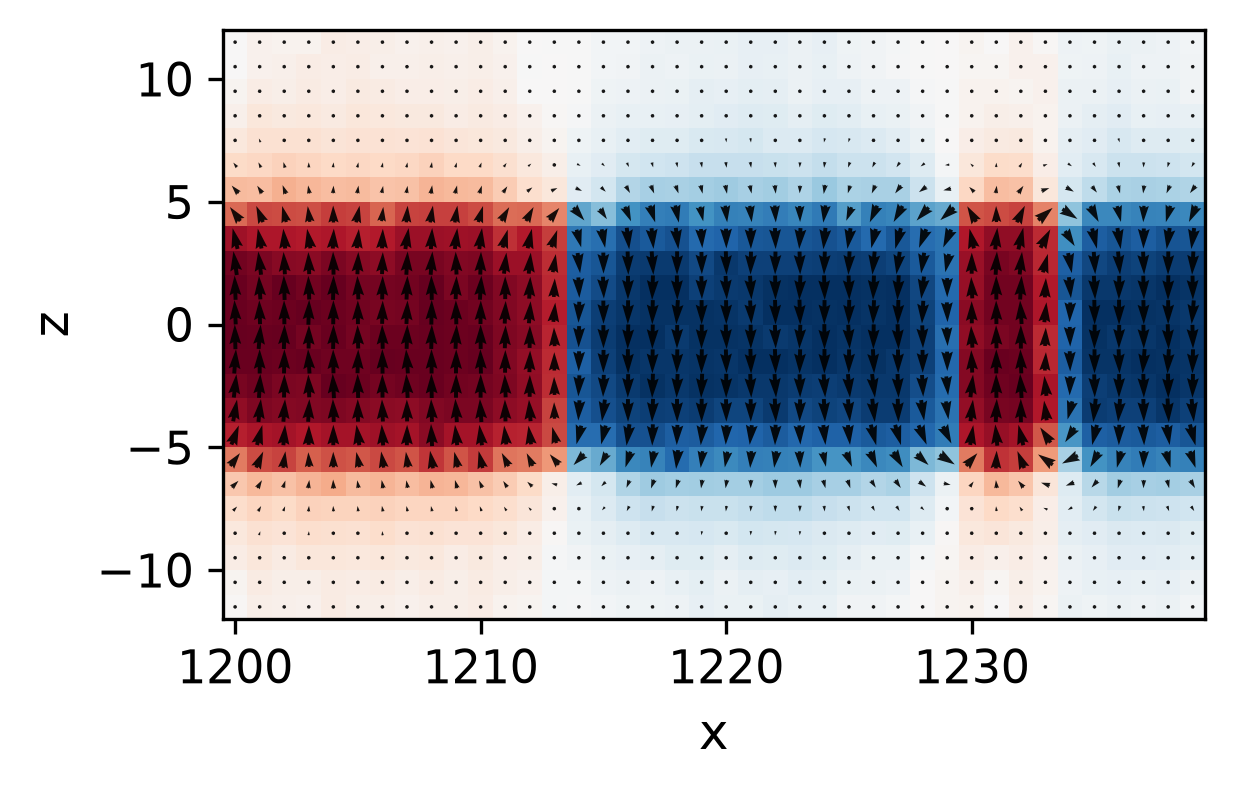

$p_x$ on $y = 460$


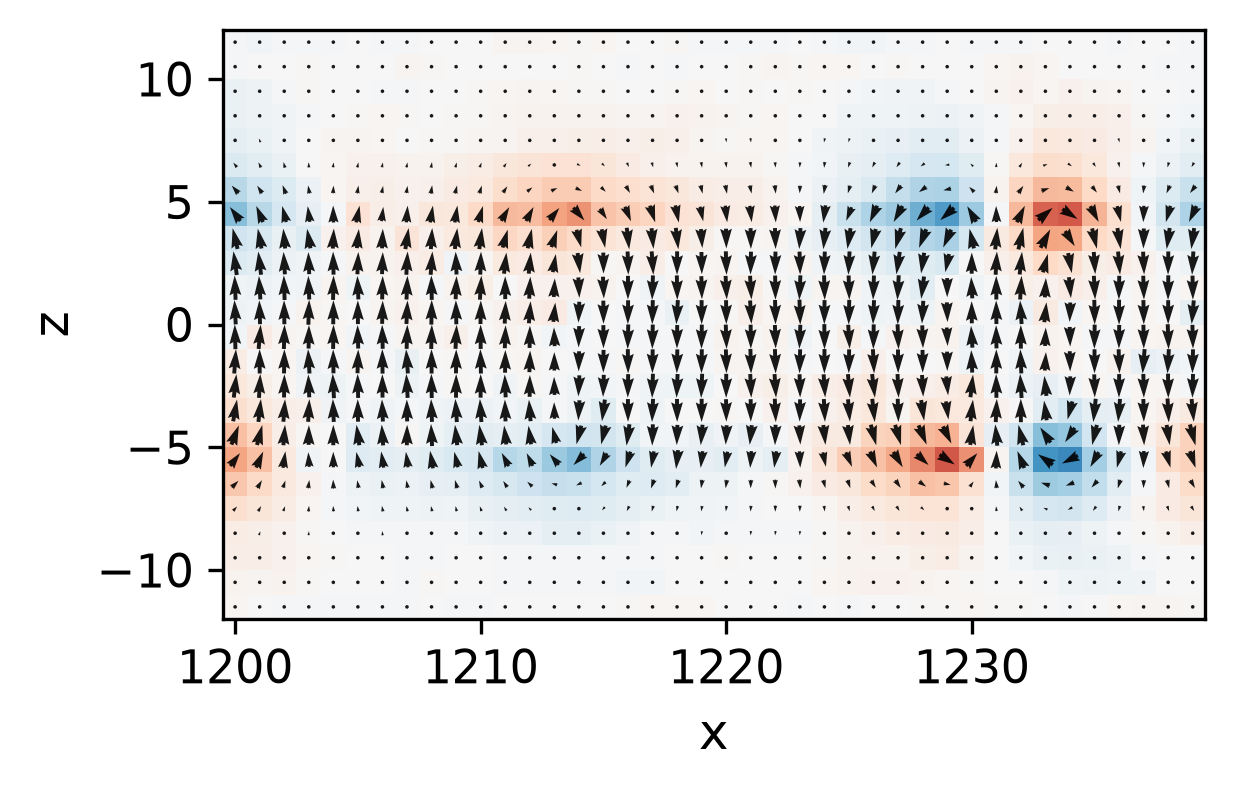

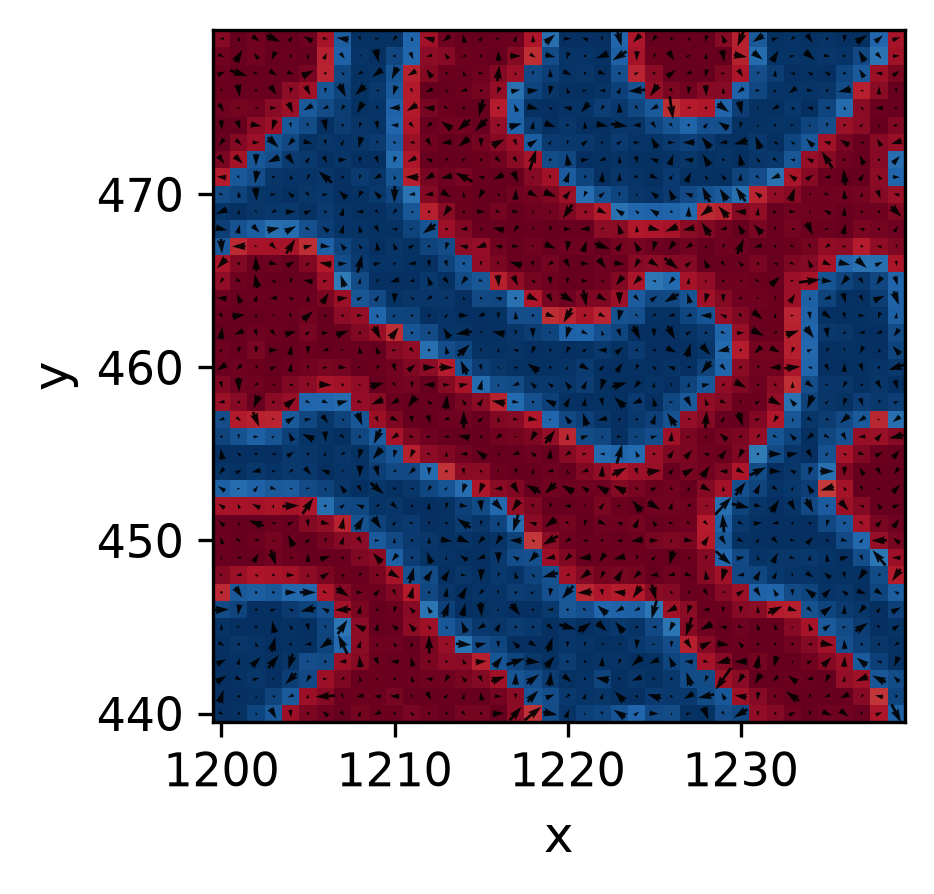

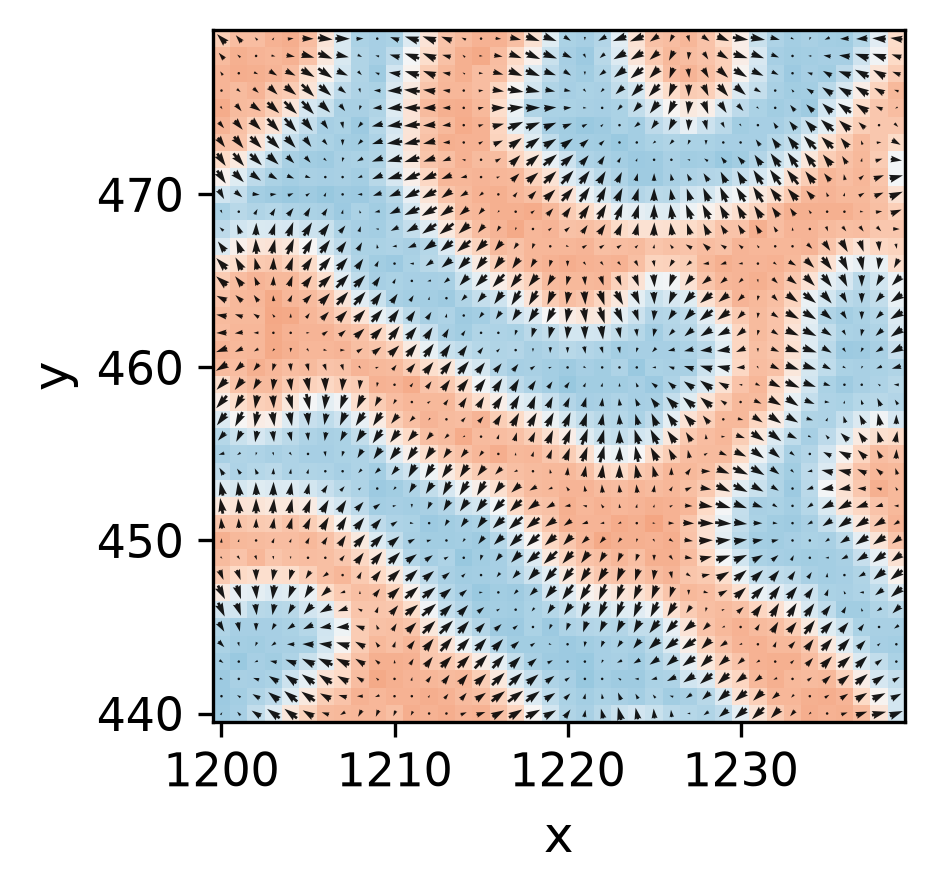

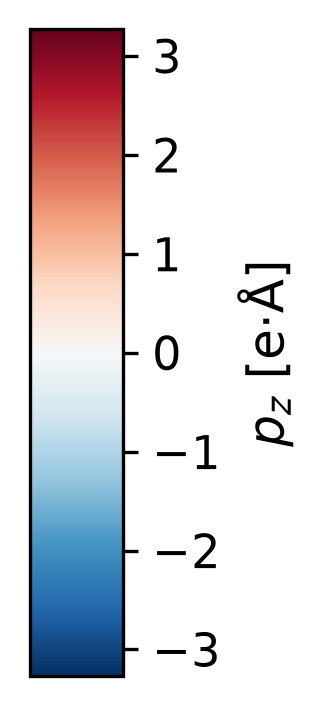

In [5]:

### Plot the windowed view
figure_dir = NOTEBOOK_DIR / "figures"
figure_dir.mkdir(exist_ok=True)
panel_cmap = "RdBu_r"

def save_figure(fig, name):
    fig.savefig(
        figure_dir / name,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()

for component, label, name in (
    (2, r"$p_z$", "xz_pz.png"),
    (0, r"$p_x$", "xz_px.png"),
):
    fig, axis = plt.subplots(figsize=(4, 3.2), constrained_layout=True)
    axis.imshow(
        section[:, :, component].T,
        origin="lower",
        extent=(
            x0 - 0.5,
            x0 + WINDOW - 0.5,
            -0.5 - z_center,
            nz - 0.5 - z_center,
        ),
        norm=color_norm,
        cmap=panel_cmap,
        aspect="equal",
    )
    quiver_plane(
        axis,
        (x0, -z_center),
        section[:, :, 0],
        section[:, :, 2],
    )
    axis.set_xlabel("x")
    axis.set_ylabel("z")
    # axis.set_title(rf"{label} on $y = {y_cut}$")
    print(rf"{label} on $y = {y_cut}$")
    save_figure(fig, name)

for layer, title, name in (
    (middle_layer, rf"middle, $z = {middle_layer}$", "xy_middle.png"),
    (top_layer, rf"top interface, $z = {top_layer}$", "xy_interface.png"),
):
    fig, axis = plt.subplots(figsize=(3, 3.1), constrained_layout=True)
    show_xy(axis, window[:, :, layer, 2], x0, y0, color_norm)
    quiver_plane(
        axis,
        (x0, y0),
        window[:, :, layer, 0],
        window[:, :, layer, 1],
    )
    axis.set_xlabel("x")
    axis.set_ylabel("y")
    # axis.set_title(title)
    save_figure(fig, name)

fig, axis = plt.subplots(figsize=(0.4, 2.8))
fig.colorbar(
    plt.cm.ScalarMappable(norm=color_norm, cmap=panel_cmap),
    cax=axis,
    orientation="vertical",
)
axis.set_ylabel(r"$p_z$ [e$\cdot$Å]")
save_figure(fig, "colorbar.png")